# How early is this flu season?

First pass: load CDC ILINet and line up every season since 1997 by week of season, so 2026–27 can be read against the others. Onset, peak and length come next.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

RAW = Path("../data/raw")
PROCESSED = Path("../data/processed")
CHARTS = Path("../charts")

## Load

The V5 snapshot gives the latest release of each week. A season runs from epidemiological week 40 to week 39 of the next year, so a week ending on or after the Saturday in early October starts a new season.

In [2]:
nat = pd.read_csv(RAW / "ilinet_wili_nation.csv", parse_dates=["reference_time"])
nat = nat[["reference_time", "value"]].rename(columns={"reference_time": "week_end", "value": "wili"})
nat = nat.sort_values("week_end").reset_index(drop=True)  # the API does not return rows in date order

def season_start_year(d):
    # Week 40 ends in the first days of October; use October 1 as the cut.
    return d.year if d.month >= 10 else d.year - 1

nat["season"] = nat["week_end"].map(season_start_year)
first = nat.groupby("season")["week_end"].transform("min")
nat["week_of_season"] = (nat["week_end"] - first).dt.days // 7 + 1
nat["label"] = nat["season"].astype(str) + "–" + (nat["season"] + 1).astype(str).str[-2:]
print(nat["week_end"].min().date(), "to", nat["week_end"].max().date(), "|", nat["season"].nunique(), "seasons")
nat.tail()

1997-10-04 to 2026-11-14 | 30 seasons


,week_end,wili,season,week_of_season,label
1420,2026-10-17,2.19703,2026,3,2026–27
1421,2026-10-24,2.44339,2026,4,2026–27
1422,2026-10-31,2.84286,2026,5,2026–27
1423,2026-11-07,3.38327,2026,6,2026–27
1424,2026-11-14,3.80078,2026,7,2026–27


## Checks

ILINet reported only October to May until the 2002–03 season. Summer weeks are missing before then and present after.

In [3]:
per_season = nat.groupby("season").size()
print(per_season.head(7))
assert nat["week_end"].is_monotonic_increasing
assert nat["wili"].notna().all()
# Before the 2002–03 season ILINet reported only from October to May (weeks 40 to 20),
# so those seasons have 33 weeks and a summer gap. From 2002–03 on, every week is present.
gaps = nat.loc[nat["week_end"].diff().dt.days.ne(7), "week_end"].iloc[1:]
assert gaps.dt.year.max() <= 2002 and gaps.dt.month.eq(10).all(), gaps
assert nat.loc[nat["season"] >= 2002, "week_end"].diff().iloc[1:].dt.days.eq(7).all()

season
1997    34
1998    33
1999    33
2000    33
2001    33
2002    52
2003    52
dtype: int64


## Every season by week

2026–27 against the rest. The 2009 pandemic is marked apart because its autumn wave is not a usual season.

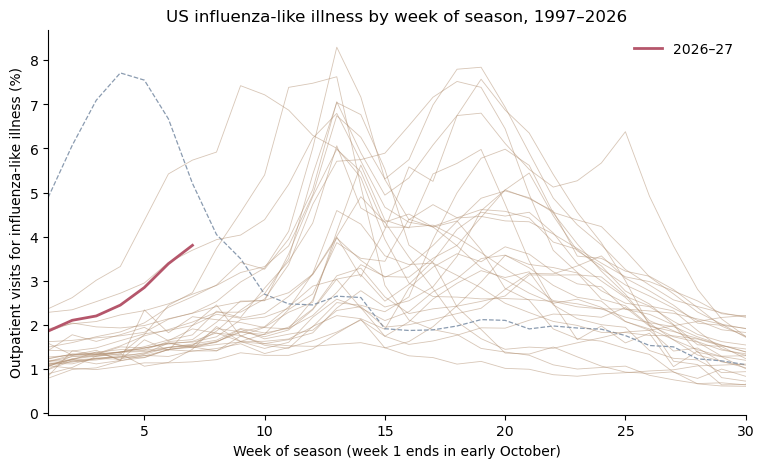

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
for s, g in nat.groupby("season"):
    if s == 2026:
        continue
    style = dict(color="#b08d6e", lw=0.6, alpha=0.5) if s != 2009 else dict(color="#8a9bb0", lw=0.9, ls="--")
    ax.plot(g["week_of_season"], g["wili"], **style)
cur = nat[nat["season"] == 2026]
ax.plot(cur["week_of_season"], cur["wili"], color="#b5566b", lw=2, label="2026–27")
ax.set_xlim(1, 30)
ax.set_xlabel("Week of season (week 1 ends in early October)")
ax.set_ylabel("Outpatient visits for influenza-like illness (%)")
ax.set_title("US influenza-like illness by week of season, 1997–2026")
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(frameon=False)
plt.show()

## Where 2026–27 stands at the same week

A first, rough comparison: each season's wILI at the latest week available for 2026–27.

In [5]:
wk = int(cur["week_of_season"].max())
same_week = nat[nat["week_of_season"] == wk].set_index("label")["wili"].sort_values(ascending=False)
rank = same_week.index.get_loc(cur["label"].iloc[0]) + 1
print(f"Week {wk} of season: 2026–27 is {same_week.iloc[rank-1]:.2f}%, rank {rank} of {len(same_week)}")
same_week.head(10)

Week 7 of season: 2026–27 is 3.80%, rank 3 of 30


label
2022–23    5.735220
2009–10    5.206326
2026–27    3.800780
2023–24    3.690300
2003–04    2.726045
2024–25    2.691700
2019–20    2.632510
2025–26    2.263360
2021–22    2.257880
1998–99    2.179748
Name: wili, dtype: float64

## Next

- Get CDC's national baseline for each season and define onset as three weeks in a row at or above it.
- Onset week, peak week, peak height and length for each season.
- Relationship between onset and size, with 2009–10 and 2020–21 handled apart.
- HHS regions and states.